# Week 5: Model Optimization and Validation
**Goal:** improve the Week 4 model (HistGradientBoosting, test RMSLE 0.4823) and prove that it generalizes to new data.

**Steps:**
1. Rebuild the Week 4 setup and record the baseline
2. Design a time-aware cross-validation (folds are built by *week*, never random)
3. Hyperparameter tuning with `RandomizedSearchCV` on those folds
4. Final evaluation on the untouched hold-out weeks (136-145)
5. Interpretation: where did the model improve, and what does it mean for the business
6. Leakage check on the mean-encoded features (the known Week 3 limitation)

## 1. Setup, data and the Week 4 split

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
N_ITER = 15            # number of random configurations to try (lower it if the search is too slow)

In [4]:
df = pd.read_csv('./Data/feature_engineered_food_demand.csv')   # change the path if needed
print(df.shape)

TARGET = 'num_orders_log'
DROP_FROM_X = ['num_orders', 'num_orders_log', 'week']
y = df[TARGET]
X = df.drop(columns=[c for c in DROP_FROM_X if c in df.columns])

# Same time-based split as Week 4: train weeks 1-135, hold-out weeks 136-145
TEST_WEEKS = 10
cutoff = df['week'].max() - TEST_WEEKS
train_mask = df['week'] <= cutoff
test_mask = ~train_mask

# Decision for Week 5: drop the three *_scaled columns. They are exact copies of the raw columns
# (correlation 1.0) and removing them did not change the Week 4 score (0.4823 -> 0.4823).
dup_cols = [c for c in X.columns if c.endswith('_scaled')]
X = X.drop(columns=dup_cols)

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]
print('Dropped duplicate columns:', dup_cols)
print(f'Features: {X.shape[1]} | Train: {len(X_train):,} rows | Hold-out: {len(X_test):,} rows')

(456548, 49)
Dropped duplicate columns: ['checkout_price_scaled', 'base_price_scaled', 'op_area_scaled']
Features: 43 | Train: 423,727 rows | Hold-out: 32,821 rows


## 2. Baseline (Week 4 model, default settings)
This is the **"before"** number. The configuration is exactly what `make_gb()` used in Week 4.

In [10]:
def rmsle(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))   # target is already log1p, so RMSE = RMSLE

def full_scores(model, Xa, ya):
    p = model.predict(Xa)
    return {'RMSLE': rmsle(ya, p), 'MAE (log)': mean_absolute_error(ya, p), 'R2 (log)': r2_score(ya, p),
            'MAE (orders)': mean_absolute_error(np.expm1(ya), np.expm1(p))}

def make_baseline():
    return HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, max_leaf_nodes=63,
                                         random_state=RANDOM_STATE)

t0 = time.time()
baseline = make_baseline().fit(X_train, y_train)
print(f'Fit time: {time.time()-t0:.0f}s')
base_train = full_scores(baseline, X_train, y_train)
base_test = full_scores(baseline, X_test, y_test)
print('Baseline train  :', {k: round(v, 4) for k, v in base_train.items()})
print('Baseline hold-out:', {k: round(v, 4) for k, v in base_test.items()})

Fit time: 24s
Baseline train  : {'RMSLE': np.float64(0.4722), 'MAE (log)': 0.3618, 'R2 (log)': 0.847, 'MAE (orders)': 71.5604}
Baseline hold-out: {'RMSLE': np.float64(0.4823), 'MAE (log)': 0.3718, 'R2 (log)': 0.8239, 'MAE (orders)': 62.7337}


## 3. Cross-validation design
**Why not random K-fold?** A random split would let the model train on weeks that come *after* the weeks it is validated on, which is the same leakage problem we avoided in Week 4. It would also make the scores look better than they really are.

**What we do instead:** expanding-window folds built by week number, using only the training weeks (1-135). Each fold trains on everything before a 10-week block and validates on that block:

| Fold | Train weeks | Validation weeks |
|---|---|---|
| 1 | 1-95 | 96-105 |
| 2 | 1-105 | 106-115 |
| 3 | 1-115 | 116-125 |
| 4 | 1-125 | 126-135 |

(Note: the CSV is sorted by meal/center and then week, **not** by week, so sklearn's default `TimeSeriesSplit` on row order would be wrong. The folds are therefore built from the `week` column.)

The hold-out weeks 136-145 are not touched by any of this. They are used once, at the end.

In [11]:
train_weeks = df.loc[train_mask, 'week'].values
VAL_STARTS = [96, 106, 116, 126]
VAL_LEN = 10

cv_folds = []
for s in VAL_STARTS:
    tr_idx = np.where(train_weeks < s)[0]
    va_idx = np.where((train_weeks >= s) & (train_weeks < s + VAL_LEN))[0]
    cv_folds.append((tr_idx, va_idx))
    print(f'Fold: train weeks 1-{s-1} ({len(tr_idx):,} rows) -> validate weeks {s}-{s+VAL_LEN-1} ({len(va_idx):,} rows)')

def cv_scores(make_model, Xtr=None, ytr=None, folds=None):
    Xtr = X_train if Xtr is None else Xtr
    ytr = y_train if ytr is None else ytr
    folds = cv_folds if folds is None else folds
    out = []
    for tr_idx, va_idx in folds:
        m = make_model().fit(Xtr.iloc[tr_idx], ytr.iloc[tr_idx])
        out.append(rmsle(ytr.iloc[va_idx], m.predict(Xtr.iloc[va_idx])))
    return np.array(out)

t0 = time.time()
base_cv = cv_scores(make_baseline)
print(f'\nBaseline CV RMSLE per fold: {base_cv.round(4)}')
print(f'Baseline CV mean = {base_cv.mean():.4f}  (std {base_cv.std():.4f})   [{time.time()-t0:.0f}s]')

Fold: train weeks 1-95 (292,958 rows) -> validate weeks 96-105 (32,408 rows)
Fold: train weeks 1-105 (325,366 rows) -> validate weeks 106-115 (32,707 rows)
Fold: train weeks 1-115 (358,073 rows) -> validate weeks 116-125 (32,834 rows)
Fold: train weeks 1-125 (390,907 rows) -> validate weeks 126-135 (32,820 rows)

Baseline CV RMSLE per fold: [0.5286 0.5276 0.4932 0.4816]
Baseline CV mean = 0.5078  (std 0.0208)   [68s]


## 4. Hyperparameter tuning
`RandomizedSearchCV` samples random combinations instead of trying every one, which is much cheaper for a dataset of 424k rows. It is scored on the week-based folds above, so the "best" setting is the one that predicts *future* weeks best, not the one that merely memorises the past.

What each setting controls:
- `learning_rate`: how big each boosting step is. Smaller = slower but usually more accurate.
- `max_leaf_nodes` / `max_depth`: how complex each tree can be. Too high = overfitting.
- `min_samples_leaf`: minimum rows per leaf. Larger = smoother, less overfit.
- `l2_regularization`: penalty on large leaf values. Larger = more conservative.
- `max_iter` with early stopping: the number of trees is chosen automatically, stopping when the score stops improving.

In [5]:
base_params = dict(max_iter=1000, early_stopping=True, n_iter_no_change=20,
                   validation_fraction=0.1, random_state=RANDOM_STATE)

param_dist = {
    'learning_rate':     [0.03, 0.05, 0.08, 0.1],
    'max_leaf_nodes':    [31, 63, 127, 255],
    'max_depth':         [None, 8, 12, 16],
    'min_samples_leaf':  [20, 50, 100, 200, 400],
    'l2_regularization': [0.0, 0.1, 1.0, 10.0],
}

search = RandomizedSearchCV(
    HistGradientBoostingRegressor(**base_params),
    param_distributions=param_dist,
    n_iter=N_ITER,
    scoring='neg_root_mean_squared_error',
    cv=cv_folds,
    refit=False,
    random_state=RANDOM_STATE,
    n_jobs=1,          # HistGradientBoosting already uses all CPU cores
    verbose=1,
)
t0 = time.time()
search.fit(X_train, y_train)
print(f'Search finished in {(time.time()-t0)/60:.1f} min')

Fitting 4 folds for each of 15 candidates, totalling 60 fits
Search finished in 32.3 min


In [6]:
res = pd.DataFrame(search.cv_results_)
res['cv_rmsle'] = -res['mean_test_score']
res['cv_std'] = res['std_test_score']
cols = ['cv_rmsle', 'cv_std'] + [f'param_{k}' for k in param_dist]
leaderboard = res.sort_values('cv_rmsle')[cols].reset_index(drop=True)
display(leaderboard.head(10).round(4))

best_row = res.loc[res['cv_rmsle'].idxmin()]
best_params = {k: best_row[f'param_{k}'] for k in param_dist}
# cleanup numpy/None types
best_params = {k: (None if pd.isna(v) else (int(v) if k in ('max_leaf_nodes','max_depth','min_samples_leaf') else float(v)))
               for k, v in best_params.items()}
print('Best parameters:', best_params)

,cv_rmsle,cv_std,param_learning_rate,param_max_leaf_nodes,param_max_depth,param_min_samples_leaf,param_l2_regularization
0,0.5055,0.0189,0.05,127,12,20,1.0
1,0.5057,0.0194,0.05,63,None,20,0.1
2,0.5061,0.0188,0.05,255,12,200,10.0
3,0.5062,0.0191,0.03,255,12,20,1.0
4,0.5062,0.0204,0.10,31,12,20,10.0
5,0.5067,0.0176,0.10,127,None,100,0.1
6,0.5068,0.0206,0.03,63,16,50,1.0
7,0.5068,0.0211,0.03,63,16,20,0.0
8,0.5071,0.0207,0.03,63,8,50,0.1
9,0.5072,0.0182,0.08,255,16,400,0.0


Best parameters: {'learning_rate': 0.05, 'max_leaf_nodes': 127, 'max_depth': 12, 'min_samples_leaf': 20, 'l2_regularization': 1.0}


### Does the improvement hold in every fold?
A tuned model is only convincing if it beats the baseline in each fold, not just on average.

,Fold,Baseline RMSLE,Tuned RMSLE,Improvement
0,1 (weeks 96-105),0.5286,0.5242,0.0045
1,2 (weeks 106-115),0.5276,0.5243,0.0033
2,3 (weeks 116-125),0.4932,0.4900,0.0032
3,4 (weeks 126-135),0.4816,0.4835,-0.0018


Baseline CV: 0.5078 +/- 0.0208
Tuned CV   : 0.5055 +/- 0.0189
Tuned beats baseline in 3 of 4 folds


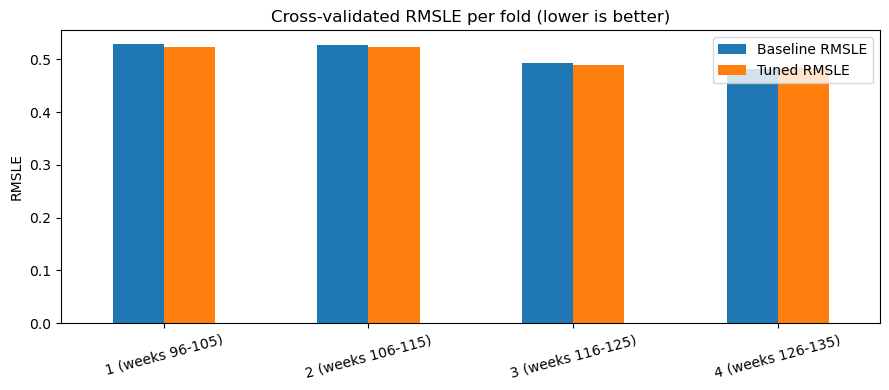

In [8]:
def make_tuned():
    return HistGradientBoostingRegressor(**base_params, **best_params)

tuned_cv = cv_scores(make_tuned)
fold_table = pd.DataFrame({
    'Fold': [f'{i+1} (weeks {s}-{s+VAL_LEN-1})' for i, s in enumerate(VAL_STARTS)],
    'Baseline RMSLE': base_cv, 'Tuned RMSLE': tuned_cv})
fold_table['Improvement'] = fold_table['Baseline RMSLE'] - fold_table['Tuned RMSLE']
display(fold_table.round(4))
print(f'Baseline CV: {base_cv.mean():.4f} +/- {base_cv.std():.4f}')
print(f'Tuned CV   : {tuned_cv.mean():.4f} +/- {tuned_cv.std():.4f}')
print('Tuned beats baseline in', int((tuned_cv < base_cv).sum()), 'of', len(base_cv), 'folds')

ax = fold_table.set_index('Fold')[['Baseline RMSLE', 'Tuned RMSLE']].plot(kind='bar', figsize=(9, 4))
ax.set_title('Cross-validated RMSLE per fold (lower is better)'); ax.set_ylabel('RMSLE'); ax.set_xlabel('')
plt.xticks(rotation=15); plt.tight_layout()
plt.savefig('Charts/24_cv_per_fold.png', dpi=300, bbox_inches='tight')
plt.show()

### Quick tuning of the Ridge baseline (for comparison)
Tuning helps simple models much less than boosted trees. This shows whether the improvement is just "any model gets better with tuning" or specific to the tree model.

In [9]:
binary_cols = [c for c in X.columns if X[c].nunique() <= 2]
continuous_cols = [c for c in X.columns if c not in binary_cols]
ridge_pipe = Pipeline([
    ('prep', ColumnTransformer([('scale', StandardScaler(), continuous_cols)], remainder='passthrough')),
    ('model', Ridge())])
ridge_cv = GridSearchCV(ridge_pipe, {'model__alpha': [0.01, 0.1, 1, 10, 100]},
                        scoring='neg_root_mean_squared_error', cv=cv_folds, refit=True)
ridge_cv.fit(X_train, y_train)
print('Best Ridge alpha:', ridge_cv.best_params_, '| CV RMSLE:', round(-ridge_cv.best_score_, 4))
print('Ridge hold-out RMSLE:', round(rmsle(y_test, ridge_cv.predict(X_test)), 4), '(Week 4 default Ridge: 0.5251)')

Best Ridge alpha: {'model__alpha': 100} | CV RMSLE: 0.5602
Ridge hold-out RMSLE: 0.5251 (Week 4 default Ridge: 0.5251)


## 5. Final evaluation on the hold-out weeks (136-145)
The tuned model is refitted on all training weeks and scored **once** on data that was never used for tuning.

In [10]:
t0 = time.time()
tuned = make_tuned().fit(X_train, y_train)
print(f'Fit time: {time.time()-t0:.0f}s | trees used (early stopping): {tuned.n_iter_}')

tuned_train = full_scores(tuned, X_train, y_train)
tuned_test = full_scores(tuned, X_test, y_test)

summary = pd.DataFrame({
    'Baseline (Week 4)': base_test,
    'Tuned (Week 5)': tuned_test}).T
summary['Improvement in RMSLE'] = [0.0, base_test['RMSLE'] - tuned_test['RMSLE']]
display(summary.round(4))
print(f"RMSLE: {base_test['RMSLE']:.4f} -> {tuned_test['RMSLE']:.4f}  "
      f"({(1 - tuned_test['RMSLE']/base_test['RMSLE'])*100:.2f}% lower)")
print(f"MAE in orders: {base_test['MAE (orders)']:.1f} -> {tuned_test['MAE (orders)']:.1f} "
      f"({base_test['MAE (orders)'] - tuned_test['MAE (orders)']:.1f} fewer orders wrong per meal-week on average)")

Fit time: 46s | trees used (early stopping): 1000


,RMSLE,MAE (log),R2 (log),MAE (orders),Improvement in RMSLE
Baseline (Week 4),0.4823,0.3718,0.8239,62.7337,0.0000
Tuned (Week 5),0.4786,0.3680,0.8265,61.8514,0.0037


RMSLE: 0.4823 -> 0.4786  (0.76% lower)
MAE in orders: 62.7 -> 61.9 (0.9 fewer orders wrong per meal-week on average)


### Is the model generalizing? (train vs cross-validation vs hold-out)
A model that memorises the training data has a very low train error and a much higher validation error. A small, stable gap means it generalizes.

In [11]:
gap = pd.DataFrame({
    'Train RMSLE':      [base_train['RMSLE'], tuned_train['RMSLE']],
    'CV RMSLE (mean)':  [base_cv.mean(),      tuned_cv.mean()],
    'CV std':           [base_cv.std(),       tuned_cv.std()],
    'Hold-out RMSLE':   [base_test['RMSLE'],  tuned_test['RMSLE']]},
    index=['Baseline', 'Tuned'])
gap['Hold-out minus train'] = gap['Hold-out RMSLE'] - gap['Train RMSLE']
display(gap.round(4))

,Train RMSLE,CV RMSLE (mean),CV std,Hold-out RMSLE,Hold-out minus train
Baseline,0.4722,0.5078,0.0208,0.4823,0.0101
Tuned,0.4405,0.5055,0.0189,0.4786,0.0381


## 6. Interpretation: where exactly did the model improve?

**A. By demand level.** In Week 4 the model over-predicted very low demand and under-predicted spikes. Does tuning change that? (Bias = actual minus predicted; positive means the model under-predicts.)

In [12]:
t = pd.DataFrame({'y_true': y_test.values,
                  'p_base': baseline.predict(X_test),
                  'p_tuned': tuned.predict(X_test)}, index=X_test.index)
t['demand_level'] = pd.qcut(t['y_true'], 5, labels=['Lowest 20%', 'Low', 'Middle', 'High', 'Highest 20%'])
for c in ['base', 'tuned']:
    t[f'err_{c}'] = (t['y_true'] - t[f'p_{c}']).abs()
    t[f'bias_{c}'] = t['y_true'] - t[f'p_{c}']

by_level = t.groupby('demand_level', observed=True).agg(
    rows=('y_true', 'size'),
    MAE_base=('err_base', 'mean'), MAE_tuned=('err_tuned', 'mean'),
    bias_base=('bias_base', 'mean'), bias_tuned=('bias_tuned', 'mean'))
display(by_level.round(4))

,rows,MAE_base,MAE_tuned,bias_base,bias_tuned
demand_level,,,,,
Lowest 20%,6624,0.5201,0.5139,-0.4256,-0.4143
Low,6827,0.3958,0.3939,0.0520,0.0540
Middle,6385,0.3661,0.3635,0.1284,0.1295
High,6500,0.3043,0.3014,0.1398,0.1357
Highest 20%,6485,0.2682,0.2627,0.1848,0.1756


**B. Negative-discount rows** (about a quarter of the data, where `checkout_price > base_price`).

In [13]:
t['has_negative_discount'] = X_test['has_negative_discount'].values
neg = t.groupby('has_negative_discount').agg(
    rows=('y_true', 'size'),
    MAE_base=('err_base', 'mean'), MAE_tuned=('err_tuned', 'mean'),
    bias_base=('bias_base', 'mean'), bias_tuned=('bias_tuned', 'mean'))
display(neg.round(4))

,rows,MAE_base,MAE_tuned,bias_base,bias_tuned
has_negative_discount,,,,,
0,23822,0.3761,0.3725,0.0123,0.0119
1,8999,0.3605,0.3561,0.0188,0.0208


**C. By week.** Does the tuned model stay accurate as the weeks move further from the training period?

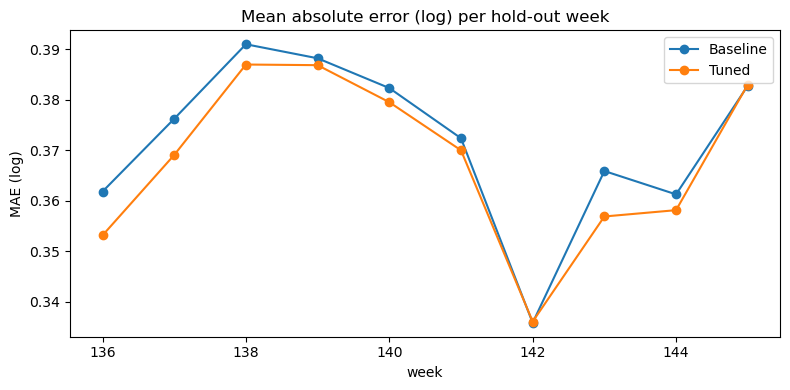

In [15]:
t['week'] = df.loc[test_mask, 'week'].values
wk = t.groupby('week')[['err_base', 'err_tuned']].mean()
ax = wk.plot(marker='o', figsize=(8, 4), title='Mean absolute error (log) per hold-out week')
ax.set_ylabel('MAE (log)'); ax.legend(['Baseline', 'Tuned']); plt.tight_layout()
plt.savefig('Charts/25_error_by_week_tuned.png', dpi=300, bbox_inches='tight')
plt.show()

**D. Actual vs predicted and residuals (tuned model).**

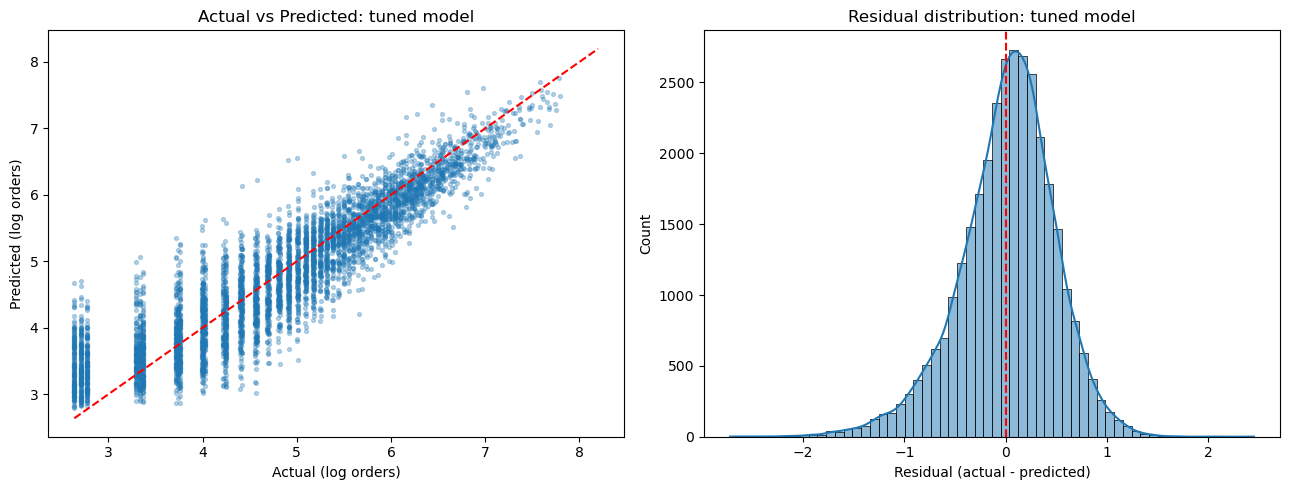

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
samp = np.random.RandomState(RANDOM_STATE).choice(len(t), size=min(5000, len(t)), replace=False)
ax[0].scatter(t['y_true'].values[samp], t['p_tuned'].values[samp], alpha=0.3, s=8)
lims = [t['y_true'].min(), t['y_true'].max()]
ax[0].plot(lims, lims, 'r--')
ax[0].set_xlabel('Actual (log orders)'); ax[0].set_ylabel('Predicted (log orders)')
ax[0].set_title('Actual vs Predicted: tuned model')
sns.histplot(t['bias_tuned'], bins=60, kde=True, ax=ax[1])
ax[1].axvline(0, color='r', ls='--'); ax[1].set_xlabel('Residual (actual - predicted)')
ax[1].set_title('Residual distribution: tuned model')
plt.tight_layout()
#plt.savefig('Charts/26_actual_vs_predicted_tuned.png', dpi=300, bbox_inches='tight')
plt.show()

**E. Feature importance after tuning** (permutation importance on a 20,000-row sample of the hold-out).

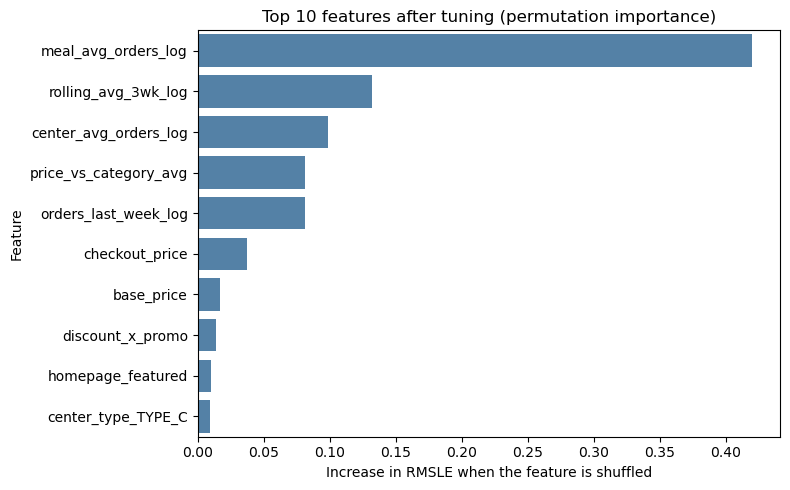

meal_avg_orders_log      0.4199
rolling_avg_3wk_log      0.1318
center_avg_orders_log    0.0987
price_vs_category_avg    0.0810
orders_last_week_log     0.0809
checkout_price           0.0373
base_price               0.0171
discount_x_promo         0.0136
homepage_featured        0.0102
center_type_TYPE_C       0.0093
dtype: float64

In [18]:
samp_idx = X_test.sample(min(20000, len(X_test)), random_state=RANDOM_STATE).index
pi = permutation_importance(tuned, X_test.loc[samp_idx], y_test.loc[samp_idx],
                            n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1,
                            scoring='neg_root_mean_squared_error')
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False)
top = imp.head(10)
plt.figure(figsize=(8, 5)); sns.barplot(x=top.values, y=top.index, color='steelblue')
plt.title('Top 10 features after tuning (permutation importance)')
plt.xlabel('Increase in RMSLE when the feature is shuffled'); plt.ylabel('Feature'); plt.tight_layout()
plt.savefig('Charts/27_feature_importance_tuned.png', dpi=300, bbox_inches='tight')
plt.show()
top.round(4)

**F. A concrete worked example** (use this in the report as evidence).

In [19]:
ex = t.copy()
ex['orders_true'] = np.expm1(ex['y_true']).round()
ex['orders_base'] = np.expm1(ex['p_base']).round()
ex['orders_tuned'] = np.expm1(ex['p_tuned']).round()
ex['miss_base'] = (ex['orders_true'] - ex['orders_base']).abs()
ex['miss_tuned'] = (ex['orders_true'] - ex['orders_tuned']).abs()
# rows where tuning helped the most in real order counts, among mid-to-high demand rows
cand = ex[ex['orders_true'] > ex['orders_true'].median()].assign(gain=lambda d: d['miss_base'] - d['miss_tuned'])
show = cand.sort_values('gain', ascending=False).head(5)[
    ['week', 'orders_true', 'orders_base', 'orders_tuned', 'miss_base', 'miss_tuned']]
display(show)

,week,orders_true,orders_base,orders_tuned,miss_base,miss_tuned
373053,136,1526.0,598.0,909.0,928.0,617.0
330564,136,998.0,651.0,907.0,347.0,91.0
257631,140,1500.0,1135.0,1386.0,365.0,114.0
10679,136,1054.0,602.0,842.0,452.0,212.0
359192,136,1309.0,793.0,1015.0,516.0,294.0


## 7. Leakage check on the mean-encoded features
In Week 3 `center_avg_orders_log` and `meal_avg_orders_log` were computed on the **whole** dataset, including the hold-out weeks. `meal_avg_orders_log` is the most important feature, so this could make every score above slightly optimistic. This section recomputes both features from **training weeks only** and re-scores the baseline and tuned models.

It needs `center_id` and `meal_id`, which were dropped before saving. If your preprocessed file is not available, the cell prints a message and skips.

In [15]:
PRE_PATH    = './Data/preprocessed_food_demand.csv'
RAW_PATH    = './Data/train.csv'
CENTER_PATH = './Data/fulfilment_center_info.csv'
MEAL_PATH   = './Data/meal_info.csv'

# 1) Turn the one-hot columns in df back into labels
def decode(prefix):
    cols = [c for c in df.columns if c.startswith(prefix)]
    return df[cols].astype(int).idxmax(axis=1).str[len(prefix):]

dfk = df[['week', 'checkout_price', 'base_price', 'emailer_for_promotion',
          'homepage_featured', 'num_orders', 'op_area']].copy()
dfk['op_area'] = dfk['op_area'].round(2)
dfk['category']    = decode('category_')
dfk['cuisine']     = decode('cuisine_')
dfk['center_type'] = decode('center_type_')
dfk['region_code'] = decode('region_code_')

# 2) Build the same columns on the raw Kaggle data
raw = (pd.read_csv(RAW_PATH)
         .merge(pd.read_csv(CENTER_PATH), on='center_id', how='left')
         .merge(pd.read_csv(MEAL_PATH), on='meal_id', how='left'))
raw['op_area'] = raw['op_area'].round(2)
raw['region_code'] = raw['region_code'].astype(str)

key = ['week', 'checkout_price', 'base_price', 'emailer_for_promotion', 'homepage_featured',
       'num_orders', 'op_area', 'category', 'cuisine', 'center_type', 'region_code']
raw_unique = raw[key + ['center_id', 'meal_id']].drop_duplicates(key, keep=False)

# 3) Match
ids = dfk[key].merge(raw_unique, on=key, how='left')[['center_id', 'meal_id']]
print('rows in df:', len(df), '| ids matched:', ids['center_id'].notna().sum(),
      '| unmatched:', ids['center_id'].isna().sum())
have_ids = ids['center_id'].notna().mean() > 0.99

rows in df: 456548 | ids matched: 455250 | unmatched: 1298


In [16]:
print(type(ids), ids.columns.tolist(), ids.shape)
print('have_ids:', have_ids)

<class 'pandas.core.frame.DataFrame'> ['center_id', 'meal_id'] (456548, 2)
have_ids: True


In [17]:
if have_ids:
    ids = ids.reset_index(drop=True)      # ids comes from the matching cell above
    ENC = [('center_id', 'center_avg_orders_log'), ('meal_id', 'meal_avg_orders_log')]

    # 1) Does mean-of-log-target reproduce the Week 3 columns? (tells us how they were defined)
    for key, col in ENC:
        full_enc = df.groupby(ids[key])[TARGET].transform('mean')
        print(f'{col}: correlation with recomputed full-data mean = {df[col].corr(full_enc):.4f}')

    def add_clean_encoding(X_frame, enc_mask):
        """Replace the two mean-encoded columns using only rows where enc_mask is True."""
        Xc = X_frame.copy()
        pos = X_frame.index
        for key, col in ENC:
            means = df.loc[enc_mask, TARGET].groupby(ids.loc[enc_mask, key]).mean()
            Xc[col] = ids.loc[pos, key].map(means).fillna(df.loc[enc_mask, TARGET].mean()).values
        return Xc

    # 2) Hold-out check: encoding learned from weeks 1-135 only
    Xtr_clean = add_clean_encoding(X_train, train_mask)
    Xte_clean = add_clean_encoding(X_test, train_mask)
    base_clean = make_baseline().fit(Xtr_clean, y_train)
    tuned_clean = make_tuned().fit(Xtr_clean, y_train)
    print('\nHold-out RMSLE with LEAK-FREE mean encoding:')
    print(f"  Baseline: {rmsle(y_test, base_clean.predict(Xte_clean)):.4f}   (with leak: {base_test['RMSLE']:.4f})")
    print(f"  Tuned   : {rmsle(y_test, tuned_clean.predict(Xte_clean)):.4f}   (with leak: {tuned_test['RMSLE']:.4f})")

    # 3) Cross-validation with encoding recomputed inside every fold
    clean_cv = {'Baseline': [], 'Tuned': []}
    for tr_idx, va_idx in cv_folds:
        fold_train_mask = pd.Series(False, index=df.index)
        fold_train_mask.loc[X_train.index[tr_idx]] = True
        Xa = add_clean_encoding(X_train.iloc[tr_idx], fold_train_mask)
        Xb = add_clean_encoding(X_train.iloc[va_idx], fold_train_mask)
        for name, mk in [('Baseline', make_baseline), ('Tuned', make_tuned)]:
            clean_cv[name].append(rmsle(y_train.iloc[va_idx], mk().fit(Xa, y_train.iloc[tr_idx]).predict(Xb)))
    for name, v in clean_cv.items():
        print(f'Leak-free CV {name}: {np.mean(v):.4f} +/- {np.std(v):.4f}  per fold: {np.round(v, 4)}')

center_avg_orders_log: correlation with recomputed full-data mean = 1.0000
meal_avg_orders_log: correlation with recomputed full-data mean = 1.0000

Hold-out RMSLE with LEAK-FREE mean encoding:
  Baseline: 0.4829   (with leak: 0.4823)
  Tuned   : 0.4789   (with leak: 0.4786)
Leak-free CV Baseline: 0.5078 +/- 0.0209  per fold: [0.5294 0.5269 0.4943 0.4806]
Leak-free CV Tuned: 0.5065 +/- 0.0190  per fold: [0.5254 0.5253 0.4913 0.484 ]


## 8. Save results for the report

In [23]:
final_table = summary.round(4)
final_table.to_csv('week5_results_summary.csv')
leaderboard.head(10).round(4).to_csv('week5_tuning_leaderboard.csv', index=False)
fold_table.round(4).to_csv('week5_cv_per_fold.csv', index=False)
print('Best parameters:', best_params)
final_table

Best parameters: {'learning_rate': 0.05, 'max_leaf_nodes': 127, 'max_depth': 12, 'min_samples_leaf': 20, 'l2_regularization': 1.0}


,RMSLE,MAE (log),R2 (log),MAE (orders),Improvement in RMSLE
Baseline (Week 4),0.4823,0.3718,0.8239,62.7337,0.0000
Tuned (Week 5),0.4786,0.3680,0.8265,61.8514,0.0037


## 9. Summary notes for the Word report
- Baseline vs tuned scores on the hold-out (section 5) and per fold (section 4)
- Why week-based expanding-window folds were used instead of random K-fold
- What each hyperparameter does and which values the search preferred
- Train vs CV vs hold-out gap (generalization evidence)
- Where the improvement came from: demand level, negative discounts, per-week error
- Feature importance after tuning and what it says about demand drivers
- Business meaning: orders of error per meal-week, impact on stock planning and wastage
- Limitations: mean-encoded features (section 7), a single hold-out period, first-week lag values